# Mieux modele avec transcriptions:

Modele qu'il connait déjà des emotions (j-hartmann).




1. Charger les données

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from google.colab import drive
from datasets import Dataset

drive.mount('/content/drive')
BASE_DIR = Path('/content/drive/MyDrive/Projet Multimedia')

EMOTION_LABELS = ['amusement', 'awe', 'contentment', 'excitement',
                  'anger', 'disgust', 'fear', 'sadness']
label2id = {l: i for i, l in enumerate(EMOTION_LABELS)}
id2label = {i: l for l, i in label2id.items()}

df = pd.read_csv(BASE_DIR / 'movie/dataset.csv')

cols = ['text', 'label']
train_ds = Dataset.from_pandas(df[df['split'] == 'train'][cols].reset_index(drop=True))
dev_ds   = Dataset.from_pandas(df[df['split'] == 'dev'][cols].reset_index(drop=True))
test_ds  = Dataset.from_pandas(df[df['split'] == 'test'][cols].reset_index(drop=True))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2. Inspectioner données

In [ ]:
print(df['split'].value_counts(),"\n")
print(df.groupby('split')['label'].value_counts(normalize=True).unstack(),"\n")  # distribució de classes

print("Nombre de mots par phrase:")
print(df['text'].str.split().str.len().describe())

split
train    1411
dev       281
test      257
Name: count, dtype: int64 

label         0         1         2         3         4         5         6  \
split                                                                         
dev    0.053381  0.099644  0.135231  0.142349  0.249110  0.110320  0.099644   
test   0.058366  0.089494  0.124514  0.112840  0.291829  0.120623  0.081712   
train  0.079376  0.090716  0.134656  0.138200  0.243090  0.119064  0.093551   

label         7  
split            
dev    0.110320  
test   0.120623  
train  0.101347   

Nombre de mots par phrase:
count    1949.000000
mean       16.636737
std        12.857113
min         1.000000
25%         8.000000
50%        14.000000
75%        21.000000
max       102.000000
Name: text, dtype: float64


3. Tokenisation

In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = 'j-hartmann/emotion-english-distilroberta-base'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fn(batch):
    return tokenizer(batch['text'], truncation=True, max_length=128)  # 128 car tres peux de phrases depassent les 100 caracteres (128 tokens ~ 100 caracteres)
                                                                      # truncation true car decoupe les phrases qui excedent la limite de 128 tokens
                                                                      # No padding

train_tok = train_ds.map(tokenize_fn, batched=True, remove_columns=['text'])
dev_tok   = dev_ds.map(tokenize_fn, batched=True, remove_columns=['text'])
test_tok  = test_ds.map(tokenize_fn, batched=True, remove_columns=['text'])

#print(train_tok[0])
#print(tokenizer.decode(train_tok[0]['input_ids']))   # torna a convertir els números en text

config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Map:   0%|          | 0/1411 [00:00<?, ? examples/s]

Map:   0%|          | 0/281 [00:00<?, ? examples/s]

Map:   0%|          | 0/257 [00:00<?, ? examples/s]

4. Metriques et entrainement

In [ ]:
pip install evaluate

In [ ]:
from transformers import (AutoModelForSequenceClassification, DataCollatorWithPadding,
                          Trainer, TrainingArguments)
from sklearn.utils.class_weight import compute_class_weight
import torch, numpy as np

train_labels = df[df['split'] == 'train']['label'].values
weights = compute_class_weight('balanced', classes=np.arange(8), y=train_labels)
weights = torch.tensor(weights, dtype=torch.float)
print(dict(zip(EMOTION_LABELS, weights.numpy().round(2))))

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

{'amusement': np.float32(1.57), 'awe': np.float32(1.38), 'contentment': np.float32(0.93), 'excitement': np.float32(0.9), 'anger': np.float32(0.51), 'disgust': np.float32(1.05), 'fear': np.float32(1.34), 'sadness': np.float32(1.23)}


In [ ]:
import torch
import evaluate
from transformers import (AutoModelForSequenceClassification, DataCollatorWithPadding,
                          Trainer, TrainingArguments, EarlyStoppingCallback)

acc_metric = evaluate.load('accuracy')   # accuracy: pourcentage de bones predictions
f1_metric  = evaluate.load('f1')         # F1-macro: regarde si on rate plus avec les classes minoritaries (on predit trop les majoritaires)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        'accuracy': acc_metric.compute(predictions=preds, references=labels)['accuracy'],
        'f1_macro': f1_metric.compute(predictions=preds, references=labels, average='macro')['f1'],
    }

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=8, id2label=id2label, label2id=label2id, ignore_mismatched_sizes=True
)                                                                   # le modele original preetrainé contient une couche de sortie avec 7 emotions
                                                                    # en ajoutant "ignore_mismatched_sizes=True" on informe au modele que c'est normale que la derniere couche soit a 8 classes et pas 7.

args = TrainingArguments(
    output_dir= str(BASE_DIR / 'models_text/results_exp2'),
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=3e-5,                 # augmenté # pas du gradient initial (decroissant a chaque pas)
    per_device_train_batch_size=16,     # chaque 16 batch calcule le gradient de la fonction qui minimise la loss
    per_device_eval_batch_size=32,
    num_train_epochs=8,                 # augmenté # nombre de fois que on passe le dataset d'entrainement
    weight_decay=0.01,                  # diminution des poids pour privilegier ceux qui sont multiples fois augmentes
    fp16=torch.cuda.is_available(),
    load_best_model_at_end=True,        # le modele garde la meilleur F1 macro des epoch
    metric_for_best_model='f1_macro',
    save_total_limit=1,
    logging_steps=20,
    report_to='none',
)

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=dev_tok,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

trainer.train()


# optimiseur: AdamW
# fonction loss: cross-entropy (car multiclas)

[transformers] You passed `num_labels=8` which is incompatible to the `id2label` map of length `7`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  329MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                        | Status   |                                                                                       
---------------------------+----------+---------------------------------------------------------------------------------------
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 768]) vs model:torch.Size([8, 768])
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([8])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


model.safetensors: reconstructing file:   0%|          |  0.00B /  329MB            

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=712, training_loss=1.3914081005567915, metrics={'train_runtime': 72.6591, 'train_samples_per_second': 155.356, 'train_steps_per_second': 9.799, 'total_flos': 216673094912928.0, 'train_loss': 1.3914081005567915, 'epoch': 8.0})

5. Avaluation et analyse des erreurs

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# 1) Resultat al dev (el que heu fet servir per triar el millor epoch)
print('DEV :', trainer.evaluate(dev_tok))

# 2) Resultat final al test (una sola vegada!)
out = trainer.predict(test_tok)
probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()
print('TEST:', out.metrics)

preds  = np.argmax(out.predictions, axis=1)
y_true = out.label_ids

print(classification_report(y_true, preds, target_names=EMOTION_LABELS, zero_division=0))
print(pd.DataFrame(confusion_matrix(y_true, preds),
                   index=EMOTION_LABELS, columns=EMOTION_LABELS))

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.821526,2.427916,8,0.195730,0.186760


DEV : {'eval_loss': 2.427915573120117, 'eval_accuracy': 0.19572953736654805, 'eval_f1_macro': 0.1867598961764136}


TEST: {'test_loss': 2.360163450241089, 'test_accuracy': 0.20233463035019456, 'test_f1_macro': 0.17897807478254457, 'test_runtime': 0.2633, 'test_samples_per_second': 976.122, 'test_steps_per_second': 34.183}
              precision    recall  f1-score   support

   amusement       0.09      0.20      0.12        15
         awe       0.14      0.13      0.13        23
 contentment       0.16      0.16      0.16        32
  excitement       0.19      0.31      0.24        29
       anger       0.43      0.25      0.32        75
     disgust       0.20      0.16      0.18        31
        fear       0.11      0.10      0.10        21
     sadness       0.18      0.19      0.19        31

    accuracy                           0.20       257
   macro avg       0.19      0.19      0.18       257
weighted avg       0.24      0.20      0.21       257

             amusement  awe  contentment  excitement  anger  disgust  fear  \
amusement            3    3            1           1      2    

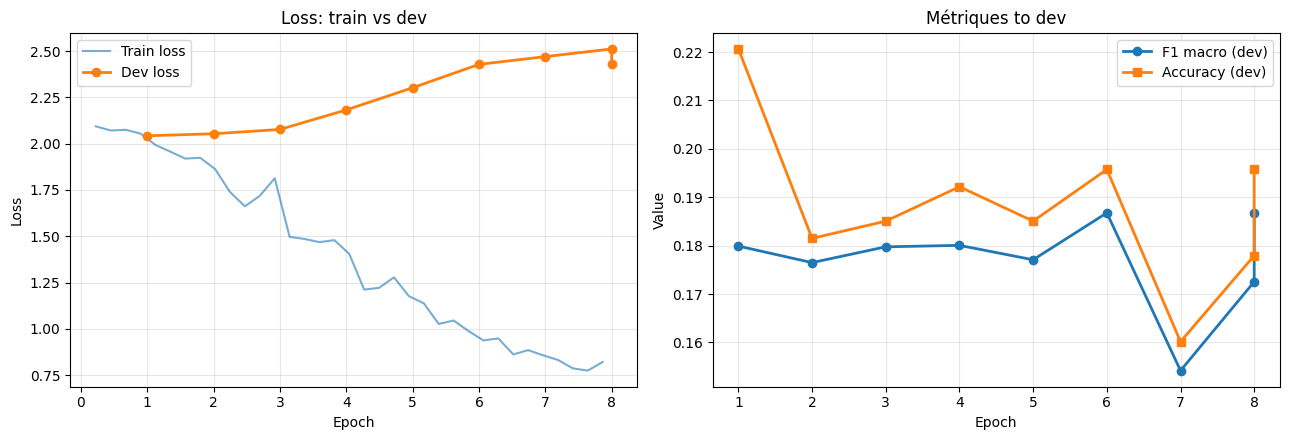

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

history = pd.DataFrame(trainer.state.log_history)

# Registres d'entrenament i d'avaluació
train_log = history[history['loss'].notna()][['epoch', 'loss']]
eval_log  = history[history['eval_loss'].notna()][['epoch', 'eval_loss', 'eval_accuracy', 'eval_f1_macro']]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Gràfic 1: pèrdua (loss) ---
axes[0].plot(train_log['epoch'], train_log['loss'], label='Train loss', alpha=0.6)
axes[0].plot(eval_log['epoch'], eval_log['eval_loss'], 'o-', label='Dev loss', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss: train vs dev')
axes[0].legend()
axes[0].grid(alpha=0.3)

# --- Gràfic 2: mètriques al dev ---
axes[1].plot(eval_log['epoch'], eval_log['eval_f1_macro'], 'o-', label='F1 macro (dev)', linewidth=2)
axes[1].plot(eval_log['epoch'], eval_log['eval_accuracy'], 's-', label='Accuracy (dev)', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Value')
axes[1].set_title('Métriques to dev')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Verifications

In [ ]:
out = trainer.predict(test_tok)
probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()
y = out.label_ids
preds = probs.argmax(1)

# a) Le modèle capte-t-il la valence (positif / négatif) ?
pos = [label2id[e] for e in ['amusement', 'awe', 'contentment', 'excitement']]
y_val, p_val = np.isin(y, pos), np.isin(preds, pos)
print('Accuracy valence :', (y_val == p_val).mean(),
      '| baseline majoritaire :', max(y_val.mean(), 1 - y_val.mean()))

# b) Top-k : la vraie émotion est-elle parmi les k plus probables ?
for k in (1, 2, 3):
    topk = np.argsort(-probs, axis=1)[:, :k]
    print(f'Top-{k} :', np.mean([y[i] in topk[i] for i in range(len(y))]))

Accuracy valence : 0.5291828793774319 | baseline majoritaire : 0.6147859922178989
Top-1 : 0.20233463035019456
Top-2 : 0.38132295719844356
Top-3 : 0.49416342412451364


In [ ]:
OUT = BASE_DIR / 'outputs_texte'
OUT.mkdir(exist_ok=True)
for split, tok_ds in [('dev', dev_tok), ('test', test_tok)]:
    out = trainer.predict(tok_ds)
    probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()
    res = pd.DataFrame(probs, columns=EMOTION_LABELS)
    res.insert(0, 'video_id', df[df['split'] == split]['video_id'].values)
    res.to_csv(OUT / f'probs_texte_dev.csv' if split == 'dev' else OUT / 'probs_texte_test.csv', index=False)
    print(split, res.shape)

dev (281, 9)


test (257, 9)


In [ ]:
# ===== Export des probabilités texte pour la fusion =====
from sklearn.metrics import f1_score

OUT = Path('/content/drive/MyDrive/PROJET_SID_2026/fusion')   # le dossier du notebook de fusion
OUT.mkdir(parents=True, exist_ok=True)

for split, tok_ds in [('dev', dev_tok), ('test', test_tok)]:
    out = trainer.predict(tok_ds)                                          # même calcul que son "probs"
    probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()
    res = pd.DataFrame(probs, columns=EMOTION_LABELS)                      # 8 colonnes, une par émotion
    res.insert(0, 'video_id', df[df['split'] == split]['video_id'].values) # + l'identifiant du clip
    res.to_csv(OUT / f'probs_texte_{split}.csv', index=False)
    f1 = f1_score(out.label_ids, probs.argmax(1), average='macro')
    print(f'{split} : {res.shape} -> {OUT / f"probs_texte_{split}.csv"}  (F1 macro = {f1:.3f})')

dev : (281, 9) -> /content/drive/MyDrive/PROJET_SID_2026/fusion/probs_texte_dev.csv  (F1 macro = 0.187)


test : (257, 9) -> /content/drive/MyDrive/PROJET_SID_2026/fusion/probs_texte_test.csv  (F1 macro = 0.179)
